# ESCM 2.0 — numerical and mechanistic audit (no custom scheduler)

> **Correction after the first executed audit (2026-11-03).** That run is **invalid** for recurrent-dynamics conclusions: Brian2 produced `RuntimeWarning: invalid value encountered in scalar divide`, NaN state warnings and zero output spikes while the independent reference generated many spikes. The culprit is the duplicated decay rate `tau_i = tau_m = 10 ms` in the coupled linear equations and the resulting singular expression in Brian2's generated `exact` updater. The standalone analytical X-to-v test passed because its two relevant constants were *not* equal. This corrected notebook changes only `tau_i` to 12 ms, adds a finite-state assertion and removes a misleading notebook-level name conflict. **All recurrent tests must be rerun; none of the previous Brian2-versus-NumPy conclusions carry over.**

## Question and acceptance standard

**Can self-sustained spiking, lateral competition, and population persistence emerge from ordinary LIF and synaptic-current equations, without the hand-managed `P` state or custom Brian2 event scheduling?**

We separate **model changes** from **simulator verification**:

1. **Analytical check.** A single, subthreshold neuron with an exponentially decaying synaptic current has a closed-form voltage trajectory. Compare Brian2 with that trajectory.
2. **Independent implementation.** Compare a small recurrent Brian2 network to a direct NumPy simulation implementing the *same clocked mathematical model*. It is independent code, but shares the declared discrete-time convention; agreement alone does **not** verify continuous-time dynamics.
3. **Continuous-time convergence.** Decrease the timestep with fixed physical time constants, input events and synaptic strengths. Compare functional outcomes and spike trains. A new model is not accepted merely because one coarse timestep works.
4. **Backend comparison.** Compare Brian2's NumPy and Cython execution targets, where Cython is available; this checks a second code-generation path, not a second simulator.
5. **Causal controls.** Remove self-excitation or lateral inhibition separately; inspect whether the expected behavior vanishes.

**What this does not claim:** Eliminating `P` changes the ESCM model. These tests cannot *prove* numerical correctness for every condition, biological plausibility, or success on full recordings. They establish whether a simple recurrent model exhibits the desired behavior independently of the *legacy scheduling tricks*.

The legacy implementation remains unchanged in notebooks 01–10. This notebook deliberately uses **no custom threshold events, no `P`, no explicit pathway `.order`, no `when=` overrides, and no modifications to Brian2 internals**. Ordinary Brian2 threshold/reset and synaptic delivery still have documented clocked semantics; we measure their effects rather than pretending they do not exist.

## 1. Equations and units

The test model is a current-based LIF network. Currents are dimensionless quantities in the same units as the model's membrane voltage:

\[
\tau_m\dot v_i=-v_i+X_i+E_i-I_i,\qquad
\tau_X\dot X_i=-X_i,\quad
\tau_E\dot E_i=-E_i,\quad
\tau_I\dot I_i=-I_i.
\]

On an external event at pixel \(i\): \(X_i\gets X_i+\beta\). On an output spike at neuron \(j\): \(E_i\gets E_i+w^E_{ij}\) and \(I_i\gets I_i+w^I_{ij}\), where all inhibitory weights are **positive** and their current enters the membrane equation with a minus sign. The self connection is an ordinary excitatory autapse. Voltage resets to zero at threshold 1.

For the first audit, choose distinct, explicitly **exploratory** time constants \((\tau_m,\tau_X,\tau_E,\tau_I)=(10,5,5,12)\,\mathrm{ms}\), with no refractory period. The inhibitory time constant is deliberately distinct from the membrane time constant: equal time constants caused the `method="exact"` symbolic state update to divide by zero in the previous run. This is a numerical-model choice to isolate the singularity, not a validated physiological setting. These are not fitted biological values. The earlier ESCM used \(0.2\,\mathrm{ms}\) for all constants and a \(0.5\,\mathrm{ms}\) clock; the values here avoid inheriting that problematic resolution ratio while we verify basic dynamics.

Spatial coupling is a short-range Gaussian excitatory kernel plus a broader inhibitory kernel. This is an *effective neural-field interaction*, not an anatomically detailed inhibitory interneuron network. **No weights are tuned to these results.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from brian2 import *
import brian2
import scipy

prefs.codegen.target = 'numpy'

# All experimental parameters fixed before running any model.
tau_m, tau_x, tau_e, tau_i = 10*ms, 5*ms, 5*ms, 12*ms
threshold, input_weight, self_weight = 1.0, 6.0, 6.0
width, height, radius = 9, 7, 2
N = width*height
end_ms = 80.0
sigma_e, sigma_i = 0.8, 2.0
lateral_e, lateral_i = 2.0, 1.5

print('Brian2', brian2.__version__, 'NumPy', np.__version__, 'SciPy', scipy.__version__)
print('Constants (ms):', float(tau_m/ms), float(tau_x/ms), float(tau_e/ms), float(tau_i/ms))
assert not np.isclose(float(tau_m/ms),float(tau_i/ms)), 'Exact solver requires a nonsingular linear update for this audit'

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Brian2 2.10.1 NumPy 2.5.4 SciPy 1.18.1
Constants (ms): 10.0 5.0 5.0 12.0


## 2. Independent analytical solution for the subthreshold LIF

For a neuron initially at rest, receiving a synaptic current \(X(0)=A\), with no further input and no spikes,

\[
X(t)=A e^{-t/\tau_X},\qquad
v(t)=A\frac{\tau_X}{\tau_X-\tau_m}
\left(e^{-t/\tau_X}-e^{-t/\tau_m}\right),\quad \tau_X\ne\tau_m.
\]

The sign and amplitude are fixed by the differential equation, not chosen to fit Brian2. We use **subthreshold** \(A=0.2\) so this test is about continuous dynamics only; threshold handling is assessed separately. The maximum absolute voltage difference is reported for several timesteps.

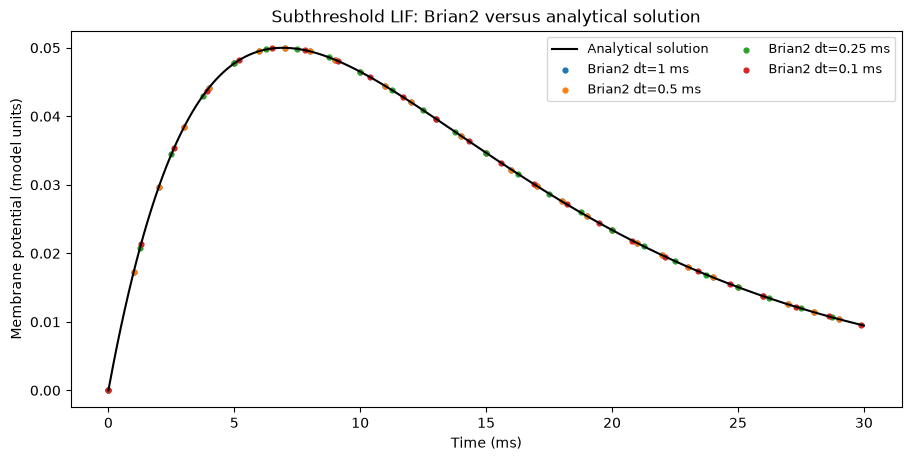

,dt_ms,max_absolute_error
0,1.00,6.245005e-17
1,0.50,2.775558e-17
2,0.25,1.110223e-16
3,0.10,4.024558e-16


In [2]:
def analytical_voltage(t_ms, amplitude=0.2):
    tm, tx = float(tau_m/ms), float(tau_x/ms)
    return amplitude*tx/(tx-tm)*(np.exp(-t_ms/tx)-np.exp(-t_ms/tm))

analytical_errors = []
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
tfine = np.linspace(0, 30, 601)
ax.plot(tfine, analytical_voltage(tfine), color='black', label='Analytical solution')
for dt_ms in (1.0, 0.5, 0.25, 0.1):
    start_scope()
    defaultclock.dt = dt_ms*ms
    neurons = NeuronGroup(1,
        'dv/dt = (-v + X)/tau_m : 1\n dX/dt = -X/tau_x : 1',
        threshold='v > 1', reset='v = 0', method='exact',
        namespace={'tau_m': tau_m, 'tau_x': tau_x})
    neurons.X = 0.2
    monitor = StateMonitor(neurons, ['v', 'X'], record=True)
    Network(neurons, monitor).run(30*ms)
    t = np.asarray(monitor.t/ms)
    voltage_trace = np.asarray(monitor.v[0])
    error = float(np.max(np.abs(voltage_trace - analytical_voltage(t))))
    analytical_errors.append((dt_ms, error))
    ax.scatter(t[::max(1, len(t)//22)], voltage_trace[::max(1, len(t)//22)], s=12,
               label=f'Brian2 dt={dt_ms:g} ms')
ax.set(xlabel='Time (ms)', ylabel='Membrane potential (model units)',
       title='Subthreshold LIF: Brian2 versus analytical solution')
ax.legend(ncol=2, fontsize=9)
plt.show()
display(pd.DataFrame(analytical_errors, columns=['dt_ms', 'max_absolute_error']))
assert max(e for _, e in analytical_errors) < 1e-10, 'Subthreshold analytical check failed'

## 3. Specify connectivity and input protocols without hidden scheduler actions

The nonself neighborhood uses integer pixel offsets \(|\Delta x|,|\Delta y|\le2\). Spatial excitatory and inhibitory weights depend on Euclidean pixel distance; the autapse uses \(w^E_{ii}=6\), \(w^I_{ii}=0\).

Five protocols test isolated activation, sequential replacement, a simultaneously activated stationary edge, a five-column moving edge, and two separate stationary edges. Camera inputs occur exactly on multiples of \(0.5\,\mathrm{ms}\), so they remain aligned under the tested refinements \(0.25,0.1,0.05\,\mathrm{ms}\).

In [3]:
source = np.repeat(np.arange(N), N)
target = np.tile(np.arange(N), N)
dx = source % width - target % width
dy = source // width - target // width
near = (source != target) & (abs(dx) <= radius) & (abs(dy) <= radius)
nonself_src, nonself_dst = source[near], target[near]
d2 = dx[near]**2 + dy[near]**2
exc_src = np.r_[np.arange(N), nonself_src]
exc_dst = np.r_[np.arange(N), nonself_dst]
exc_w = np.r_[np.full(N, self_weight), lateral_e*np.exp(-d2/(2*sigma_e**2))]
inh_src, inh_dst = nonself_src, nonself_dst
inh_w = lateral_i*np.exp(-d2/(2*sigma_i**2))

assert np.all(exc_w >= 0) and np.all(inh_w >= 0)
assert np.count_nonzero(exc_src == exc_dst) == N
assert np.all(inh_src != inh_dst)
assert len(set(zip(exc_src, exc_dst))) == len(exc_src)
assert len(set(zip(inh_src, inh_dst))) == len(inh_src)
assert set(zip(inh_src, inh_dst)) == set(zip(inh_dst, inh_src))
print('Excitatory connections:', len(exc_src), '| inhibitory connections:', len(inh_src))

center = 3*width + 4
edge_rows = np.arange(1, 6)
edge_cols = np.arange(2, 7)

def moving_edge(interval=4.0):
    return (np.array([row*width+col for col in edge_cols for row in edge_rows]),
            np.array([1.0+step*interval for step in range(len(edge_cols)) for _ in edge_rows]))

protocols = {
    'single': (np.array([center]), np.array([1.0])),
    'sequential': (np.array([center, center+1]), np.array([1.0, 15.0])),
    'stationary_edge': (edge_rows*width+4, np.ones(5)),
    'moving_edge': moving_edge(),
    'two_edges': (np.r_[edge_rows*width+1, edge_rows*width+7], np.ones(10)),
}
for name, (ids, times) in protocols.items():
    assert np.allclose(times/0.5, np.rint(times/0.5)), name
    assert len(set(zip(ids, np.rint(times/0.5).astype(int)))) == len(ids), name
print('Protocols:', ', '.join(protocols))

Excitatory connections: 1131 | inhibitory connections: 1068
Protocols: single, sequential, stationary_edge, moving_edge, two_edges


## 4. Standard Brian2 model — no `P`, custom events, or altered schedule

All excitatory presynaptic spikes contribute to the same `E_post` trace via `+=`; inhibitory spikes contribute to a separate `I_post` trace. Consequently, **no two synaptic pathways compete to assign the same state variable**. External input updates only `X_post`.

The ordinary Brian2 event order determines when a presynaptic spike is delivered relative to threshold/reset. This is an inherent convention of any clocked simulator, but here we do not override it. We print the Brian2 schedule once for inspection.

The two control switches `self_strength` and `inhibition_strength` permit causal ablations without changing connectivity geometry, event routing, or simulator scheduler.

In [4]:
def brian_run(ids, times_ms, dt_ms=0.1, backend='numpy',
              self_strength=self_weight, inhibition_strength=lateral_i,
              show_schedule=False, refractory_ms=0.0):
    start_scope()
    prefs.codegen.target = backend
    defaultclock.dt = dt_ms*ms
    params = dict(tau_m=tau_m, tau_x=tau_x, tau_e=tau_e, tau_i=tau_i,
                  threshold_value=threshold, input_weight_value=input_weight)
    camera = SpikeGeneratorGroup(N, ids, times_ms*ms)
    eqs = """
    dv/dt = (-v + X + E - I)/tau_m : 1
    dX/dt = -X/tau_x : 1
    dE/dt = -E/tau_e : 1
    dI/dt = -I/tau_i : 1
    """
    if refractory_ms:
        eqs = eqs.replace('dv/dt = (-v + X + E - I)/tau_m : 1',
                          'dv/dt = (-v + X + E - I)/tau_m : 1 (unless refractory)')
    neurons = NeuronGroup(N, eqs, threshold='v > threshold_value',
                          reset='v = 0', method='exact', namespace=params,
                          refractory=refractory_ms*ms)
    feed = Synapses(camera, neurons, on_pre='X_post += input_weight_value',
                    namespace=params)
    feed.connect(j='i')
    excitation = Synapses(neurons, neurons, 'w : 1 (constant)',
                          on_pre='E_post += w')
    excitation.connect(i=exc_src, j=exc_dst)
    excitation.w = exc_w*np.where(exc_src == exc_dst,
                                   self_strength/self_weight, 1.0)
    inhibition = Synapses(neurons, neurons, 'w : 1 (constant)',
                          on_pre='I_post += w')
    inhibition.connect(i=inh_src, j=inh_dst)
    inhibition.w = inh_w*(inhibition_strength/lateral_i)
    output = SpikeMonitor(neurons)
    net = Network(camera, neurons, feed, excitation, inhibition, output)
    if show_schedule:
        print(net.scheduling_summary())
    net.run(end_ms*ms)
    # Fail loudly instead of mistaking a NaN simulation for zero activity.
    for state_name in ('v', 'X', 'E', 'I'):
        values = np.asarray(getattr(neurons, state_name)[:])
        if not np.all(np.isfinite(values)):
            raise FloatingPointError(
                f'Brian2 produced nonfinite {state_name} values at '
                f'dt={dt_ms} ms, backend={backend}. '
                'Do not interpret spike counts from this run.'
            )
    return np.asarray(output.t/ms), np.asarray(output.i, dtype=int)

raster_time, raster_ids = brian_run(*protocols['single'], show_schedule=True)
print(f'Isolated stimulus: {len(raster_ids)} output spikes; {len(np.unique(raster_ids))} active neurons')

                  object                    |                  part of                  |       Clock dt       |    when    | order | active
--------------------------------------------+-------------------------------------------+----------------------+------------+-------+-------
neurongroup_stateupdater (StateUpdater)     | neurongroup (NeuronGroup)                 | 100. us (every step) | groups     |     0 |  yes  
neurongroup_spike_thresholder (Thresholder) | neurongroup (NeuronGroup)                 | 100. us (every step) | thresholds |     0 |  yes  
spikegeneratorgroup (SpikeGeneratorGroup)   | spikegeneratorgroup (SpikeGeneratorGroup) | 100. us (every step) | thresholds |     0 |  yes  
spikemonitor (SpikeMonitor)                 | spikemonitor (SpikeMonitor)               | 100. us (every step) | thresholds |     1 |  yes  
synapses_1_pre (SynapticPathway)            | synapses_1 (Synapses)                     | 100. us (every step) | synapses   |    -1 |  yes  
synapses_2_pr

## 5. Independent NumPy reference for the same clocked model

For verification, implement the four-dimensional linear ODE exactly over each clock interval, **without using Brian2**. When current \(z\) decays with \(\tau_z\), the exact membrane contribution over one interval \(h\) is

\[
 v(t+h)=e^{-h/\tau_m}v(t)+\sum_z s_z z(t)
 \frac{\tau_z}{\tau_z-\tau_m}\left(e^{-h/\tau_z}-e^{-h/\tau_m}\right),
\]

where \((s_X,s_E,s_I)=(+1,+1,-1)\). A time constant equal to \(\tau_m\) uses the continuous limit \((h/\tau_m)e^{-h/\tau_m}\).

**Clock convention (explicit):** update the continuous state over one step; at its endpoint threshold neurons, reset their voltage, deliver external inputs and recurrent spikes. This is deliberately **not assumed to match Brian2's event ordering exactly**; it is an independent clocked implementation with a disclosed convention. When comparing, report differences rather than forcing parity through hand-picked event offsets.

The actual analytical check above is independent of this convention. Numerical refinement is necessary to establish whether differences diminish with \(h\).

In [5]:
def numpy_run(ids, times_ms, dt_ms=0.1,
              self_strength=self_weight, inhibition_strength=lateral_i):
    nt = int(round(end_ms/dt_ms))
    assert np.isclose(nt*dt_ms, end_ms)
    input_ticks = np.rint(np.asarray(times_ms)/dt_ms).astype(int)
    assert np.allclose(input_ticks*dt_ms, times_ms)
    events = [[] for _ in range(nt+1)]
    for ix, tick in zip(ids, input_ticks):
        events[tick].append(int(ix))

    tm, tx, te, ti = [float(t/ms) for t in (tau_m, tau_x, tau_e, tau_i)]
    am = np.exp(-dt_ms/tm)
    ax, ae, ai = [np.exp(-dt_ms/t) for t in (tx, te, ti)]
    def contribution(t, a):
        if np.isclose(t, tm):
            return dt_ms/tm*am
        return t/(t-tm)*(a-am)
    cx, ce, ci = [contribution(t, a) for t, a in ((tx, ax), (te, ae), (ti, ai))]
    v, X, E, I = (np.zeros(N) for _ in range(4))
    output_ticks, output_ids = [], []
    self_mask = exc_src == exc_dst
    eweights = exc_w*np.where(self_mask, self_strength/self_weight, 1.0)
    iweights = inh_w*(inhibition_strength/lateral_i)

    # Camera events at t=0 affect the first integration interval.
    if events[0]:
        np.add.at(X, events[0], input_weight)
    for tick in range(1, nt+1):
        v = am*v + cx*X + ce*E - ci*I
        X *= ax
        E *= ae
        I *= ai
        fired = np.flatnonzero(v > threshold)
        if len(fired):
            output_ticks.extend([tick]*len(fired))
            output_ids.extend(fired.tolist())
            v[fired] = 0.0
            mask_e = np.isin(exc_src, fired)
            mask_i = np.isin(inh_src, fired)
            np.add.at(E, exc_dst[mask_e], eweights[mask_e])
            np.add.at(I, inh_dst[mask_i], iweights[mask_i])
        if events[tick]:
            np.add.at(X, events[tick], input_weight)
    return np.array(output_ticks)*dt_ms, np.array(output_ids, dtype=int)

comparison = []
for dt_ms in (0.5, 0.25, 0.1, 0.05):
    for name in ('single', 'sequential'):
        ids, times = protocols[name]
        t_b, i_b = brian_run(ids, times, dt_ms=dt_ms)
        t_n, i_n = numpy_run(ids, times, dt_ms=dt_ms)
        shared = min(len(t_b), len(t_n))
        overlap = np.count_nonzero((i_b[:shared] == i_n[:shared]) &
                                   (abs(t_b[:shared] - t_n[:shared]) <= dt_ms+1e-8))
        comparison.append((dt_ms, name, len(t_b), len(t_n),
                           overlap/shared if shared else np.nan))
print('Independent NumPy clocked model versus Brian2 (NOT required to match exactly):')
display(pd.DataFrame(comparison, columns=['dt_ms', 'protocol', 'Brian2_spikes',
                                         'NumPy_spikes', 'prefix_fraction_within_dt']))

Independent NumPy clocked model versus Brian2 (NOT required to match exactly):


,dt_ms,protocol,Brian2_spikes,NumPy_spikes,prefix_fraction_within_dt
0,0.50,single,128,149,0.0
1,0.50,sequential,128,149,0.0
2,0.25,single,135,288,0.0
3,0.25,sequential,135,288,0.0
4,0.10,single,135,699,0.0
5,0.10,sequential,135,699,0.0
6,0.05,single,136,1363,0.0
7,0.05,sequential,136,1363,0.0


## 6. Convergence of the functionally important outcomes

The primary observables are **not** exact spike-list parity across timesteps; they are (1) the number of active neurons in the final 20 ms, (2) the fraction of desired final-edge pixels active, (3) obsolete active pixels, and (4) output spike rate. We also report the same observables for the independent NumPy implementation.

The final edge for the moving protocol consists of the five pixels in its last column. The first 20 stimulated pixels constitute obsolete positions. For the stationary edge the five input pixels are the desired representation.

This experiment uses no fitting or parameter selection. A result is **numerically suspect** if its functional observables change substantially across the two finest tested steps. A stable result might still be scientifically poor.

Timesteps: 100%|██████████| 5/5 [00:03<00:00,  1.41it/s]


,engine,dt_ms,protocol,active,target_active,obsolete_active,outside_active,spikes,max_neuron_rate_hz
0,Brian2,0.500,single,11,1,0,10,128,225.0
1,NumPy,0.500,single,1,1,0,0,149,1862.5
2,Brian2,0.500,stationary_edge,14,2,0,12,117,187.5
3,NumPy,0.500,stationary_edge,2,2,0,0,307,1812.5
4,Brian2,0.500,moving_edge,10,0,3,7,109,162.5
5,NumPy,0.500,moving_edge,4,0,4,0,566,1812.5
6,Brian2,0.250,single,11,1,0,10,135,237.5
7,NumPy,0.250,single,1,1,0,0,288,3600.0
8,Brian2,0.250,stationary_edge,14,2,0,12,119,200.0
9,NumPy,0.250,stationary_edge,2,2,0,0,587,3512.5


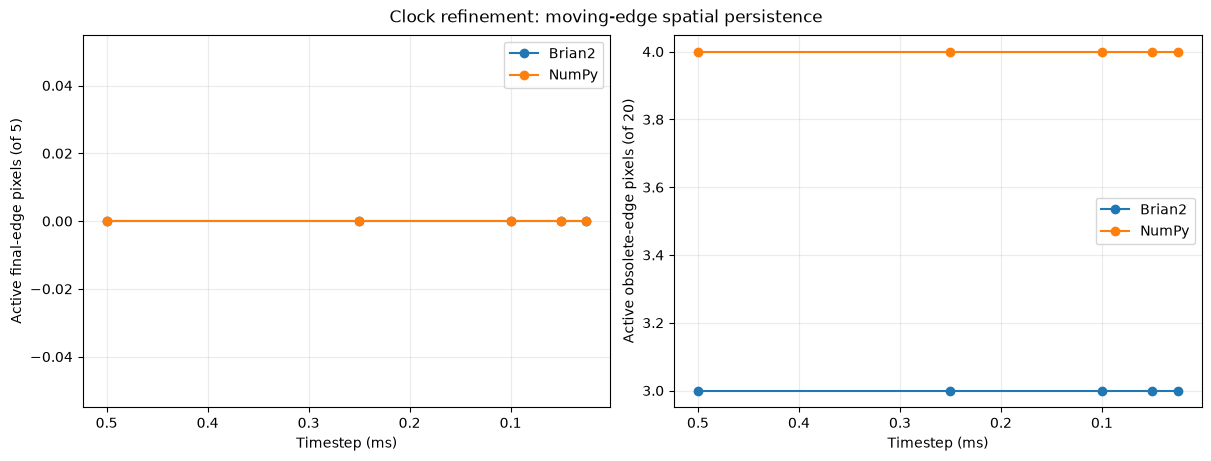

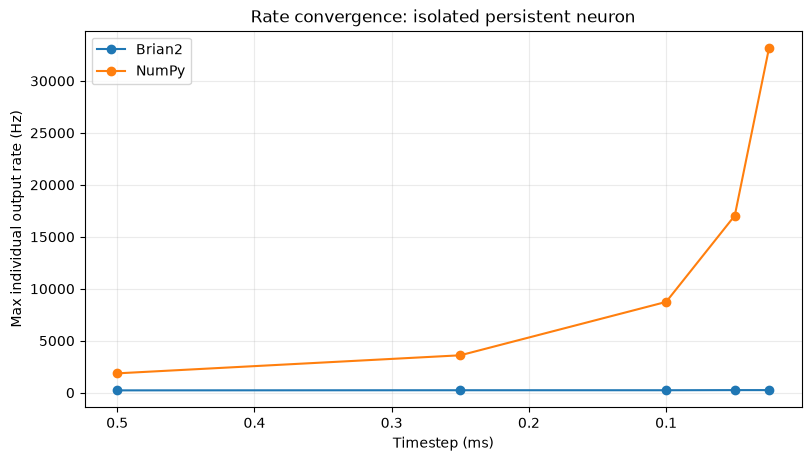

In [6]:
def measure(name, t, ids):
    active = np.unique(ids[(t >= 60.0) & (t < end_ms)])
    if name == 'moving_edge':
        target = edge_rows*width+edge_cols[-1]
        obsolete = np.concatenate([edge_rows*width+x for x in edge_cols[:-1]])
    elif name == 'stationary_edge':
        target = edge_rows*width+4
        obsolete = np.array([], dtype=int)
    else:
        target = np.unique(protocols[name][0])
        obsolete = np.array([], dtype=int)
    return dict(active=len(active), target_active=int(np.isin(target, active).sum()),
                obsolete_active=int(np.isin(obsolete, active).sum()),
                outside_active=int((~np.isin(active, protocols[name][0])).sum()),
                spikes=len(ids),
                max_neuron_rate_hz=float(np.bincount(ids, minlength=N).max()/
                                         (end_ms/1000.0)))

convergence = []
for step in tqdm((0.5, 0.25, 0.1, 0.05, 0.025), desc='Timesteps'):
    for name in ('single', 'stationary_edge', 'moving_edge'):
        stimulus = protocols[name]
        for engine, run in (('Brian2', brian_run), ('NumPy', numpy_run)):
            t, ix = run(*stimulus, dt_ms=step)
            convergence.append(dict(engine=engine, dt_ms=step, protocol=name,
                                    **measure(name, t, ix)))
convergence = pd.DataFrame(convergence)
display(convergence)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for engine in ('Brian2', 'NumPy'):
    section = convergence[(convergence.engine == engine) &
                          (convergence.protocol == 'moving_edge')]
    axes[0].plot(section.dt_ms, section.target_active, 'o-', label=engine)
    axes[1].plot(section.dt_ms, section.obsolete_active, 'o-', label=engine)
for ax, ylabel in zip(axes, ('Active final-edge pixels (of 5)',
                              'Active obsolete-edge pixels (of 20)')):
    ax.set(xlabel='Timestep (ms)', ylabel=ylabel)
    ax.invert_xaxis()
    ax.legend()
    ax.grid(alpha=0.25)
fig.suptitle('Clock refinement: moving-edge spatial persistence')
plt.show()

# A stable *active set* can hide numerical runaway: measure spike rate explicitly.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for engine in ('Brian2', 'NumPy'):
    section = convergence[(convergence.engine == engine) &
                          (convergence.protocol == 'single')]
    ax.plot(section.dt_ms, section.max_neuron_rate_hz, 'o-', label=engine)
ax.set(xlabel='Timestep (ms)', ylabel='Max individual output rate (Hz)',
       title='Rate convergence: isolated persistent neuron')
ax.invert_xaxis()
ax.legend()
ax.grid(alpha=0.25)
plt.show()

### Diagnostic: standard refractory dynamics

A LIF model without refractory can develop arbitrarily high firing frequencies if every recurrent spike adds further excitatory current. That is a **model instability**, not a Brian2 backend bug. An effective biological absolute refractory period places a lower bound on the interspike interval.

Compare the **same** network with and without an ordinary 2 ms Brian2 refractory period. With refractory enabled, membrane voltage is held at the reset value using Brian2's standard `(unless refractory)` flag; synaptic traces continue decaying. This *changes the model* and is **not** a numerical fix or a substitute for proving convergence. If refractory prevents runaway but spatial selectivity remains poor, the next task is to revise the neural dynamics rather than the scheduler.

Native refractory control: 100%|██████████| 5/5 [00:06<00:00,  1.38s/it]


,dt_ms,refractory_ms,protocol,active,target_active,obsolete_active,outside_active,spikes,max_neuron_rate_hz
0,0.500,0.0,single,11,1,0,10,128,225.0
1,0.500,0.0,moving_edge,10,0,3,7,109,162.5
2,0.500,2.0,single,11,1,0,10,111,162.5
3,0.500,2.0,moving_edge,9,0,1,8,101,100.0
4,0.250,0.0,single,11,1,0,10,135,237.5
5,0.250,0.0,moving_edge,8,0,3,5,115,200.0
6,0.250,2.0,single,11,1,0,10,111,162.5
7,0.250,2.0,moving_edge,12,0,2,10,103,100.0
8,0.100,0.0,single,11,1,0,10,135,237.5
9,0.100,0.0,moving_edge,8,0,3,5,117,212.5


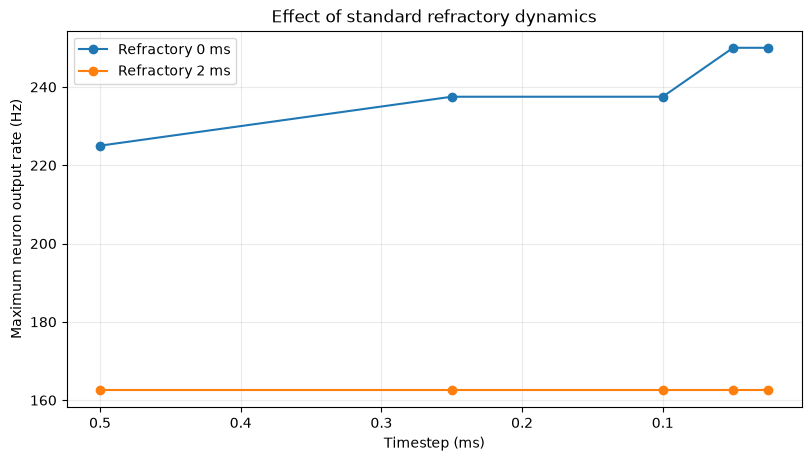

In [7]:
refractory_rows = []
for dt_ms in tqdm((0.5, 0.25, 0.1, 0.05, 0.025), desc='Native refractory control'):
    for refractory_ms in (0.0, 2.0):
        for name in ('single', 'moving_edge'):
            t, ids = brian_run(*protocols[name], dt_ms=dt_ms,
                               refractory_ms=refractory_ms)
            refractory_rows.append(dict(dt_ms=dt_ms, refractory_ms=refractory_ms,
                                        protocol=name, **measure(name, t, ids)))
refractory_results = pd.DataFrame(refractory_rows)
display(refractory_results)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for refractory_ms in (0.0, 2.0):
    d = refractory_results[(refractory_results.protocol == 'single') &
                           (refractory_results.refractory_ms == refractory_ms)]
    ax.plot(d.dt_ms, d.max_neuron_rate_hz, 'o-',
            label=f'Refractory {refractory_ms:g} ms')
ax.set(xlabel='Timestep (ms)', ylabel='Maximum neuron output rate (Hz)',
       title='Effect of standard refractory dynamics')
ax.invert_xaxis()
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 7. Brian2 backend consistency

Switch from Brian2's NumPy runtime backend to its Cython runtime backend **without changing the equations or input events**. Exact ticks and neuron IDs are expected to match when both backends implement the same clocked model with the same floating-point decisions. Near-threshold floating-point differences can also cause spike-time changes; report them rather than silently accepting or rejecting.

A missing Cython compiler is an **unavailable test**, not evidence that both backends agree. This test does not check the old custom scheduler, since the new model does not contain it.

In [8]:
backend_rows = []
for name in ('single', 'moving_edge'):
    stim = protocols[name]
    t_numpy, i_numpy = brian_run(*stim, dt_ms=0.1, backend='numpy')
    try:
        t_cython, i_cython = brian_run(*stim, dt_ms=0.1, backend='cython')
        identical = (np.array_equal(i_numpy, i_cython) and
                     np.array_equal(np.rint(t_numpy/0.1).astype(int),
                                    np.rint(t_cython/0.1).astype(int)))
        backend_rows.append((name, len(i_numpy), len(i_cython), identical, 'executed'))
    except Exception as exc:
        backend_rows.append((name, len(i_numpy), np.nan, np.nan,
                             f'NOT VERIFIED: {type(exc).__name__}: {str(exc)[:400]}'))
display(pd.DataFrame(backend_rows,
    columns=['protocol', 'NumPy_spikes', 'Cython_spikes', 'exact_match', 'status']))
prefs.codegen.target = 'numpy'

,protocol,NumPy_spikes,Cython_spikes,exact_match,status
0,single,135,135,True,executed
1,moving_edge,117,117,True,executed


## 8. Causal ablations without changing the scheduler

For each control we keep the **same topology and external stimulus**. We only set the self-autapse weight or inhibitory amplitude to zero. An isolated input should not generally sustain autonomous firing without self-excitation. Removing inhibition should reduce competition but may leave obsolete spatial traces. These are testable predictions, not guaranteed outcomes.

In [9]:
ablation_rows = []
for name in ('single', 'sequential', 'moving_edge'):
    for condition, self_gain, inh_gain in (
        ('full', self_weight, lateral_i),
        ('no_self', 0.0, lateral_i),
        ('no_inhibition', self_weight, 0.0),
    ):
        t, ids = brian_run(*protocols[name], dt_ms=0.05,
                           self_strength=self_gain, inhibition_strength=inh_gain)
        ablation_rows.append(dict(protocol=name, condition=condition,
                                  **measure(name, t, ids)))
display(pd.DataFrame(ablation_rows))

,protocol,condition,active,target_active,obsolete_active,outside_active,spikes,max_neuron_rate_hz
0,single,full,11,1,0,10,136,250.0
1,single,no_self,11,1,0,10,136,250.0
2,single,no_inhibition,63,1,0,62,1074,250.0
3,sequential,full,11,1,0,10,136,250.0
4,sequential,no_self,11,1,0,10,136,250.0
5,sequential,no_inhibition,63,2,0,61,1077,250.0
6,moving_edge,full,8,0,3,5,122,212.5
7,moving_edge,no_self,8,0,3,5,122,212.5
8,moving_edge,no_inhibition,63,5,20,38,1146,250.0


## 9. What would constitute a reliable result?

- **Numerical validity:** The analytical LIF test passes; independent NumPy behavior becomes consistent with Brian2 under timestep refinement; Brian2 runtime backends agree or differences are explicitly explained.
- **Mechanistic validity:** Self-excitation and inhibition ablations have distinct, interpretable effects. Neither mechanism is accidentally implemented through custom event ordering.
- **Scientific functionality:** Isolated stimulation produces a persistent output representation; moving structures suppress obsolete positions without collapsing all active neurons; performance is stable across fine timesteps.

**Do not automatically promote this architecture to the main ESCM model.** A correct, scheduler-free model may fail the intended task. If it does, investigate the equations themselves (membrane and synaptic timescales, balance of excitation/inhibition, adaptation, or circuit topology) rather than returning to hand-tuned Brian2 event phases.

**Audit provenance:** record the executed notebook, Brian2/NumPy/SciPy versions and the relevant Git commit. This notebook contains *screening tests*, not a proof of full continuous-time equivalence or robustness to all input classes.